In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'C:\Users\lenovo\Downloads\DADS\July_18th&19th\Files_19th\Statitics_Project\ab_data.csv')
df.head(10)

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1
5,936923,2017-01-10 15:20:49.083499,control,old_page,0
6,679687,2017-01-19 03:26:46.940749,treatment,new_page,1
7,719014,2017-01-17 01:48:29.539573,control,old_page,0
8,817355,2017-01-04 17:58:08.979471,treatment,new_page,1
9,839785,2017-01-15 18:11:06.610965,treatment,new_page,1


In [3]:
print("Sample size of the data:", "\n", df.shape, "\n")
print("Info of null values and data types: ", "\n")
print(df.info())

print("Null values in all columns:","\n")
print(df.isnull().sum(), "\n")

print("Duplicates in data:", df.duplicated().sum())

Sample size of the data: 
 (294478, 5) 

Info of null values and data types:  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB
None
Null values in all columns: 

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64 

Duplicates in data: 0


In [4]:
df.describe()

,user_id,converted
count,294478.000000,294478.000000
mean,787974.124733,0.119659
std,91210.823776,0.324563
min,630000.000000,0.000000
25%,709032.250000,0.000000
50%,787933.500000,0.000000
75%,866911.750000,0.000000
max,945999.000000,1.000000


In [5]:
# Randamization of groups
print(df['group'].value_counts(), "\n")

print("Percentage of two groups:", "\n")
print(df['group'].value_counts(normalize=True)*100, '\n')

# verify mismatches with groups and landing page
mismatches = df[
              ((df['group'] == 'control') & (df['landing_page'] != 'old_page')) | 
              ((df['group'] == 'treatment') & (df['landing_page'] != 'new_page'))
              ]

mismatches_count = mismatches['group'].value_counts()
print("Mismatch between group and landing page:", "\n")
print(mismatches_count)


group
treatment    147276
control      147202
Name: count, dtype: int64 

Percentage of two groups: 

group
treatment    50.012565
control      49.987435
Name: proportion, dtype: float64 

Mismatch between group and landing page: 

group
treatment    1965
control      1928
Name: count, dtype: int64


In [6]:
# Remove mismatches 
df = df[
        ((df['group'] == 'control') & (df['landing_page'] == 'old_page')) | 
        ((df['group'] == 'treatment') & (df['landing_page'] == 'new_page'))
        ]

mismatches_after = df[
              ((df['group'] == 'control') & (df['landing_page'] != 'old_page')) | 
              ((df['group'] == 'treatment') & (df['landing_page'] != 'new_page'))
              ]
# Verify mismatch to be zero
mismatches_count_after = mismatches_after['group'].value_counts()
print("Mismatch between group and landing page:", "\n")
print(mismatches_count_after)

Mismatch between group and landing page: 

Series([], Name: count, dtype: int64)


In [7]:
# Conversion rates

conversion_rate = df.groupby('group')['converted'].mean()
print(conversion_rate, "\n")

conversion_control = df[df['group']=='control']['converted'].mean()
conversion_treatment = df[df['group']=='treatment']['converted'].mean()
print(f"control conversion is:{conversion_control:.2f}")
print(f"treatment conversion is:{conversion_treatment:.2f}")

group
control      0.120386
treatment    0.118807
Name: converted, dtype: float64 

control conversion is:0.12
treatment conversion is:0.12


In [8]:
from scipy.stats import ttest_ind, chi2_contingency, t as t_dist

In [9]:
# T-tests
t_stat, p_value = ttest_ind(conversion_control, conversion_treatment) 
print(f"t-statistic: {t_stat:.4f}, p-value: {p_value:.4f}", '\n') 
if p_value < 0.05: 
    print("Statistically significant difference at 95% confidence") 
else: 
    print("No significant difference detected")


t-statistic: nan, p-value: nan 

No significant difference detected


C:\Users\lenovo\anaconda3\Lib\site-packages\scipy\stats\_stats_py.py:6316: RuntimeWarning: invalid value encountered in scalar divide
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df


In [10]:
# Chi-tests

contingency_table = pd.crosstab(df['group'], df['converted'])
print(contingency_table, '\n')

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"chi_test statitics: {chi2:.3f} & {p_value:.3f}")

if p_value < 0.05: 
    print("Statistically significant difference at 95% confidence") 
else: 
    print("No significant difference detected")

converted       0      1
group                   
control    127785  17489
treatment  128047  17264 

chi_test statitics: 1.705 & 0.192
No significant difference detected


In [11]:
# Confidence interval for control group
conversion_control = df[df['group']=='control']['converted']
conversion_treatment = df[df['group']=='treatment']['converted']

n_control = len(conversion_control)
mean_control = conversion_control.mean()
std_control = conversion_control.std()

se_control = std_control/np.sqrt(n_control)

ci = t_dist.interval(0.95, n_control-1, loc = mean_control, scale=se_control)

print(f"95% of CI for control: [{ci[0]:.2f},{ci[1]:.2f}]")

95% of CI for control: [0.12,0.12]


In [12]:
# Confidence interval for treatment group

n_treatment = len(conversion_treatment)
mean_treatment = conversion_treatment.mean()
std_treatment = conversion_treatment.std()

se_treatment = std_treatment/np.sqrt(n_treatment)

ci_treatment = t_dist.interval(0.95, n_treatment-1, loc = mean_treatment, scale=se_treatment)

print(f"95% of CI for control: [{ci_treatment[0]:.2f},{ci_treatment[1]:.2f}]")

95% of CI for control: [0.12,0.12]


In [13]:
# pooled std and cohen_d

pooled_std = np.sqrt((std_control**2 + std_treatment**2)/2)
cohen_d = (mean_treatment-mean_control)/pooled_std

print(f"{cohen_d:.2f}")

-0.00


In [14]:
X = df[['converted']]
X

,converted
0,0
1,0
2,0
3,0
4,1
...,...
294473,0
294474,0
294475,0
294476,0


In [15]:
from sklearn.cluster import KMeans

In [16]:
# K -means clustering algorithm

wcss = []

for i in range(1,11):
    km = KMeans(n_clusters= i)
    km.fit(X)
    wcss.append(km.inertia_)

C:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\base.py:1365: ConvergenceWarning: Number of distinct clusters (2) found smaller than n_clusters (3). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
C:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\base.py:1365: ConvergenceWarning: Number of distinct clusters (2) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
C:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\base.py:1365: ConvergenceWarning: Number of distinct clusters (2) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
C:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\base.py:1365: ConvergenceWarning: Number of distinct clusters (2) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
C:\Users\lenovo\anaconda3\Lib\site-packa

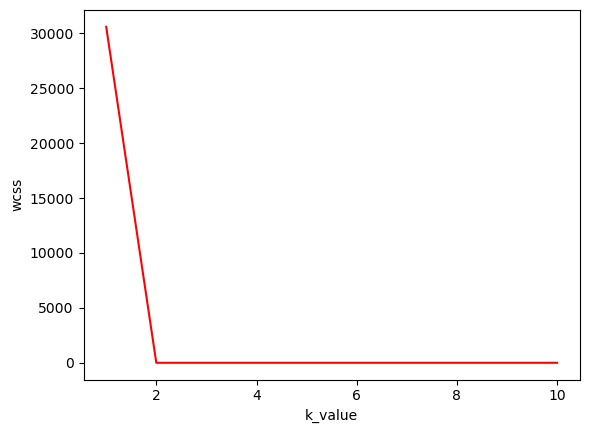

In [17]:
plt.plot(range(1,11), wcss, color ='red')
plt.xlabel("k_value")
plt.ylabel("wcss")
plt.show()

In [18]:
km1 = KMeans(n_clusters=2)
#km1.fit(X)
y= km1.fit_predict(X)

df['converted_predict']= y
df.head()

,user_id,timestamp,group,landing_page,converted,converted_predict
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,1


In [19]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(X , y)
print(accuracy)

1.0


In [22]:
# Frequency of converted and non_converted customers

count_converted = df['converted'].value_counts()

print("no of non converted customers: ", count_converted.get(0,0))
print("no of converted customers: ", count_converted.get(1,1))

conversion_rate = count_converted.get(1,0)/ len(df)*100
print(f"{conversion_rate:.2f} %")

no of non converted customers:  255832
no of converted customers:  34753
11.96 %


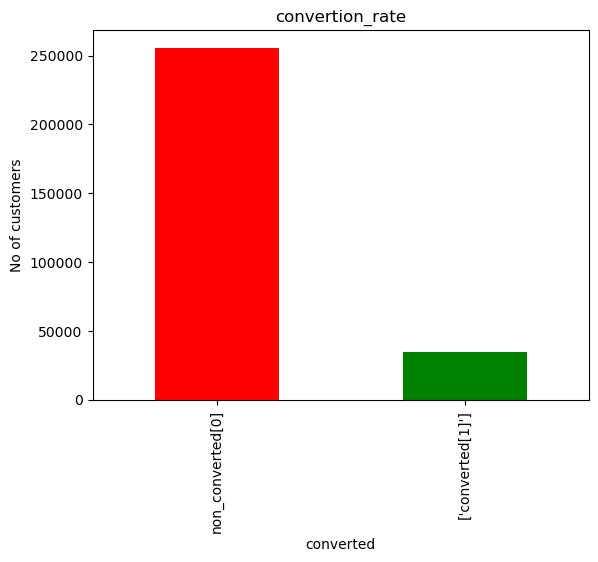

In [23]:
count_converted.plot(kind="bar", color = ['red', 'green'])
plt.xticks([0,1], ['non_converted[0]', ['converted[1]']])

plt.ylabel('No of customers')
plt.title('convertion_rate')
plt.show()